# 04 · Interpretación de resultados del clustering

Este notebook final interpreta las soluciones finales obtenidas en el anterior sin volver a seleccionar ni entrenar algoritmos.

Las soluciones finales fijadas en el notebook anterior son:

- **Universo general**: K-Means sobre PCA con **k = 3**.
- **Universo específico**: K-Means sobre PCA con **k = 2**.

Los tamaños obtenidos de cada cluster son los siguientes:

- **Universo general**: 4.238, 3.042 y 328 municipios.
- **Universo específico**: 614 y 617 municipios.

In [21]:
import os
import pickle
from getpass import getpass

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import redshift_connector

from IPython.display import display

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

pd.set_option('display.max_columns', 180)
pd.set_option('display.max_rows', 180)

Nos conectamos a Redshift para importar los datos de la capa 'curated'.

In [22]:
host = "redshift-tfm-curated.159012148774.eu-west-3.redshift-serverless.amazonaws.com"
database = "redshift-tfm-curated"
user = "tfm_admin"
password = "ldq!Zl>e>7CXzAkZa8Y+jU!_3j$4G8N>3%+>_JAH3m`)<)"
port = 5439

conn = redshift_connector.connect(
    host=host,
    database=database,
    user=user,
    password=password,
    port=port
)

QUERY = f"""
SELECT *
FROM curated.municipios
ORDER BY codigo_ine
"""

with conn.cursor() as cursor:
    cursor.execute(QUERY)
    df = cursor.fetch_dataframe()

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]:,}')
display(df.head())

Filas: 8,132 | Columnas: 107


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,codigo_provincia,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciale

## Cargar los artefactos de preprocesamiento y PCA

In [23]:
BUCKET = "s3-tfm-athena-results-159012148774-eu-west-3"
s3_client = boto3.client("s3")

def load_pickle_s3(universe: str, filename: str):
    key = f"clustering/{universe}/artifacts/{filename}"
    print(f"Cargando s3://{BUCKET}/{key}")

    response = s3_client.get_object(
        Bucket=BUCKET,
        Key=key,
    )

    return pickle.loads(response["Body"].read())


preprocessor_general = load_pickle_s3("general", "preprocessor.pkl")
preprocessor_specific = load_pickle_s3("specific", "preprocessor.pkl")

pca_general = load_pickle_s3("general", "pca.pkl")
pca_specific = load_pickle_s3("specific", "pca.pkl")

features_general = list(preprocessor_general["features"])
features_specific = list(preprocessor_specific["features"])

print(f"Features general: {len(features_general)}")
print(f"Features específico: {len(features_specific)}")
print(f"Componentes PCA general: {pca_general.n_components_}")
print(f"Componentes PCA específico: {pca_specific.n_components_}")

Cargando s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/general/artifacts/preprocessor.pkl
Cargando s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/preprocessor.pkl
Cargando s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/general/artifacts/pca.pkl
Cargando s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/pca.pkl
Features general: 29
Features específico: 48
Componentes PCA general: 17
Componentes PCA específico: 23


## Reconstruir los universos y validar las etiquetas

In [24]:
df_general = df.loc[df["cluster_general"].notna()].copy()
df_specific = df.loc[df["cluster_specific"].notna()].copy()

df_general["cluster_general"] = df_general["cluster_general"].astype(int)
df_specific["cluster_specific"] = df_specific["cluster_specific"].astype(int)

df_specific["cluster_general"] = pd.to_numeric(
    df_specific["cluster_general"],
    errors="coerce"
).astype("Int64")

summary_universes = pd.DataFrame([
    {
        "universo": "general",
        "municipios": len(df_general),
        "clusters": df_general["cluster_general"].nunique(),
        "etiquetas": sorted(df_general["cluster_general"].unique().tolist()),
    },
    {
        "universo": "specific",
        "municipios": len(df_specific),
        "clusters": df_specific["cluster_specific"].nunique(),
        "etiquetas": sorted(df_specific["cluster_specific"].unique().tolist()),
    },
])

display(summary_universes)

general_codes = set(df_general["codigo_ine"].astype(str))
specific_codes = set(df_specific["codigo_ine"].astype(str))

# Verificamos que todos los municipios contados en el específico se incluyen en el general
print("Específico ⊂ general:", specific_codes.issubset(general_codes))

PROVINCIAS_EXCLUIDAS = preprocessor_general.get(
    "excluded_provinces",
    ["Araba/Álava", "Bizkaia", "Gipuzkoa", "Navarra"]
)

# Verificamos que se han excluido correctamente los municipios deseados
excluded_check = df.loc[
    df["provincia"].isin(PROVINCIAS_EXCLUIDAS),
    ["provincia", "cluster_general", "cluster_specific"]
]

print(
    "Municipios excluidos con cluster_general no nulo:",
    int(excluded_check["cluster_general"].notna().sum())
)

,universo,municipios,clusters,etiquetas
0,general,7608,3,"[0, 1, 2]"
1,specific,1231,2,"[0, 1]"


Específico ⊂ general: True
Municipios excluidos con cluster_general no nulo: 0


## Reconstrucción del espacio estandarizado (StandardScaler) y PCA

In [25]:
def apply_saved_preprocessor(data: pd.DataFrame, prep: dict) -> pd.DataFrame:
    features = list(prep["features"])
    imputer_features = list(prep["imputer"].feature_names_in_)

    missing = [c for c in imputer_features if c not in data.columns]
    if missing:
        raise KeyError(
            f"Faltan columnas necesarias para la imputación: {missing}"
        )

    X_imp_input = (
        data[imputer_features]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    X_imp = pd.DataFrame(
        prep["imputer"].transform(X_imp_input),
        index=X_imp_input.index,
        columns=imputer_features,
    )

    X_proc = X_imp[features].copy()

    for c, bounds in prep.get("winsor_bounds", {}).items():
        if c in X_proc.columns:
            lower, upper = bounds
            X_proc[c] = X_proc[c].clip(lower=lower, upper=upper)

    for c in prep.get("log_features", []):
        if c in X_proc.columns:
            X_proc[c] = np.log1p(X_proc[c])

    scaler_features = list(prep["scaler"].feature_names_in_)
    X_proc = X_proc[scaler_features]

    values = prep["scaler"].transform(X_proc)

    return pd.DataFrame(
        values,
        index=X_proc.index,
        columns=scaler_features,
    )


def transform_pca(X_scaled: pd.DataFrame, pca) -> pd.DataFrame:
    values = pca.transform(X_scaled)

    return pd.DataFrame(
        values,
        index=X_scaled.index,
        columns=[
            f"PC{i}"
            for i in range(1, values.shape[1] + 1)
        ],
    )


X_general_scaled = apply_saved_preprocessor(
    df_general,
    preprocessor_general
)

X_specific_scaled = apply_saved_preprocessor(
    df_specific,
    preprocessor_specific
)

X_general_pca = transform_pca(
    X_general_scaled,
    pca_general
)

X_specific_pca = transform_pca(
    X_specific_scaled,
    pca_specific
)

print("General:", X_general_scaled.shape, "→ PCA", X_general_pca.shape)
print("Específico:", X_specific_scaled.shape, "→ PCA", X_specific_pca.shape)

General: (7608, 29) → PCA (7608, 17)
Específico: (1231, 48) → PCA (1231, 23)


## Tamaño de los clusters

Antes de interpretar los perfiles de cada cluster y analizar posibles patrones se revisará el peso de cada grupo en los dos universos.

In [26]:
def cluster_sizes(data: pd.DataFrame, cluster_col: str) -> pd.DataFrame:
    out = (
        data[cluster_col]
        .value_counts()
        .sort_index()
        .rename_axis("cluster")
        .reset_index(name="n_municipios")
    )

    out["pct_municipios"] = (
        out["n_municipios"] / len(data) * 100
    )

    return out


sizes_general = cluster_sizes(
    df_general,
    "cluster_general"
)

sizes_specific = cluster_sizes(
    df_specific,
    "cluster_specific"
)

print("GENERAL")
display(sizes_general.round(2))

print("ESPECÍFICO")
display(sizes_specific.round(2))

GENERAL


,cluster,n_municipios,pct_municipios
0,0,4238,55.70
1,1,3042,39.98
2,2,328,4.31


ESPECÍFICO


,cluster,n_municipios,pct_municipios
0,0,614,49.88
1,1,617,50.12


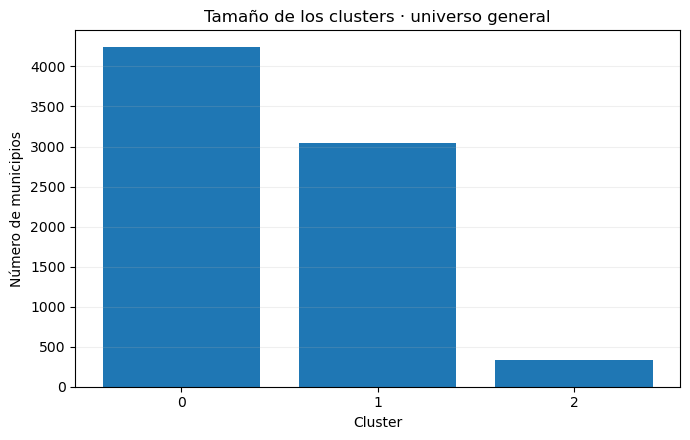

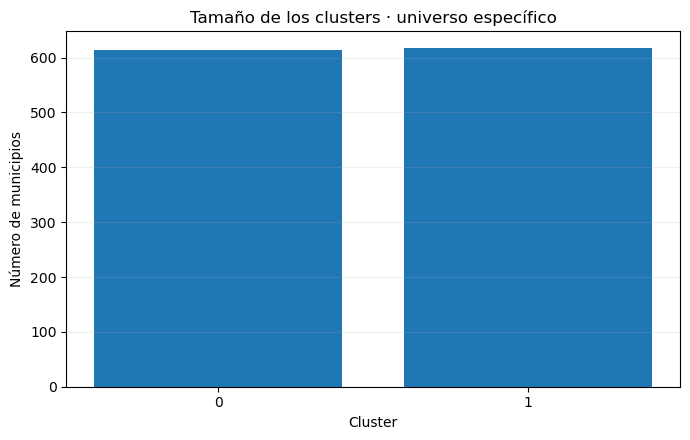

In [27]:
def plot_cluster_sizes(
    sizes: pd.DataFrame,
    title: str
):
    plt.figure(figsize=(7, 4.5))

    plt.bar(
        sizes["cluster"].astype(str),
        sizes["n_municipios"],
    )

    plt.xlabel("Cluster")
    plt.ylabel("Número de municipios")
    plt.title(title)
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()


plot_cluster_sizes(
    sizes_general,
    "Tamaño de los clusters · universo general"
)

plot_cluster_sizes(
    sizes_specific,
    "Tamaño de los clusters · universo específico"
)

Se puede apreciar que el último cluster de la segmentación general supone un porcentaje bastante menor que los otros dos grupos (4%), mientras que en el clustering más específico los dos grupos seleccionados están bastante balanceados.

# Perfil estandarizado de los clusters

Para cada variable se calcula la media estandarizada de los municipios pertenecientes a cada cluster. Después se mide la **capacidad discriminante descriptiva** de la variable como la diferencia entre el mayor y el menor perfil medio de los clusters.

Utilizaremos esta medida para ordenar las variables según cuánto separan descriptivamente a los grupos obtenidos.

In [28]:
def standardized_cluster_profile(
    X_scaled: pd.DataFrame,
    labels: pd.Series,
) -> pd.DataFrame:
    labels = labels.loc[X_scaled.index].astype(int)

    profile = (
        X_scaled
        .assign(cluster=labels)
        .groupby("cluster")
        .mean()
        .T
    )

    profile.columns = [
        f"cluster_{int(c)}"
        for c in profile.columns
    ]

    return profile


def discriminating_variables(
    profile: pd.DataFrame
) -> pd.DataFrame:
    out = pd.DataFrame(index=profile.index)

    out["profile_min"] = profile.min(axis=1)
    out["profile_max"] = profile.max(axis=1)
    out["range_z"] = (
        out["profile_max"] - out["profile_min"]
    )
    out["abs_max_z"] = profile.abs().max(axis=1)

    return (
        out
        .sort_values(
            ["range_z", "abs_max_z"],
            ascending=False
        )
        .reset_index(names="variable")
    )


profile_general_z = standardized_cluster_profile(
    X_general_scaled,
    df_general["cluster_general"]
)

profile_specific_z = standardized_cluster_profile(
    X_specific_scaled,
    df_specific["cluster_specific"]
)

discriminators_general = discriminating_variables(
    profile_general_z
)

discriminators_specific = discriminating_variables(
    profile_specific_z
)

print("Variables más discriminantes · GENERAL")
display(discriminators_general.head(20).round(4))

print("Variables más discriminantes · ESPECÍFICO")
display(discriminators_specific.head(20).round(4))

Variables más discriminantes · GENERAL


,variable,profile_min,profile_max,range_z,abs_max_z
0,transacciones_nuevas_por_1000_inmuebles_reside...,-0.4269,3.1646,3.5915,3.1646
1,diferencia_transacciones_nuevas_5_anios_por_10...,-0.1742,3.1237,3.2979,3.1237
2,diferencia_transacciones_nuevas_3_anios_por_10...,-0.2139,3.0219,3.2357,3.0219
3,diferencia_transacciones_nuevas_1_anio_por_100...,-0.2042,2.7003,2.9045,2.7003
4,densidad_poblacion_hab_km2,-0.6515,0.9289,1.5805,0.9289
5,porcentaje_superficie_urbana,-0.5626,0.9642,1.5269,0.9642
6,edad_media_2025,-0.8382,0.6630,1.5012,0.8382
7,valor_catastral_residencial_medio_eur,-0.6127,0.7972,1.4100,0.7972
8,inmuebles_residenciales_por_1000_habitantes,-0.7685,0.5983,1.3669,0.7685
9,transacciones_por_1000_inmuebles_residenciales,-0.4232,0.9423,1.3654,0.9423


Variables más discriminantes · ESPECÍFICO


,variable,profile_min,profile_max,range_z,abs_max_z
0,alquiler_colectiva_aproximado_eur_m2,-0.7375,0.7339,1.4715,0.7375
1,alquiler_precio_colectiva_rango_intercuartilico,-0.7103,0.7069,1.4172,0.7103
2,alquiler_unifamiliar_aproximado_eur_m2,-0.7100,0.7066,1.4166,0.7100
3,alquiler_precio_unifamiliar_rango_intercuartilico,-0.6986,0.6952,1.3938,0.6986
4,esfuerzo_alquiler_unifamiliar_pct,-0.6982,0.6948,1.3929,0.6982
5,esfuerzo_alquiler_colectiva_pct,-0.6093,0.6063,1.2156,0.6093
6,valor_catastral_residencial_medio_eur,-0.6022,0.5993,1.2015,0.6022
7,porcentaje_superficie_urbana,-0.5984,0.5955,1.1939,0.5984
8,densidad_poblacion_hab_km2,-0.5926,0.5897,1.1823,0.5926
9,renta_neta_media_hogar_eur,-0.5575,0.5548,1.1123,0.5575


Según los resultados obtenidos, podemos afirmar que, a priori, las variables que más separan los clusters del universo general están relacionadas con las transacciones de inmuebles residenciales.

Por otro lado, para el caso más específico de los municipios con más de 5.000 habitantes, las variables que más diferencian los dos grupos describen el comportamiento del alquiler, que son justamente las variables más relevantes que no se han podido incluir en la segmentación general ante la falta de cobertura.

## Mapas de calor de las variables más discriminantes

Los mapas de calor muestran el perfil medio estandarizado de cada cluster en las variables que más diferencian a los grupos.

La lectura debe hacerse **por filas**:

- Valores mayores indican que ese cluster se sitúa relativamente alto en esa variable.
- Valores menores indican una posición relativa baja

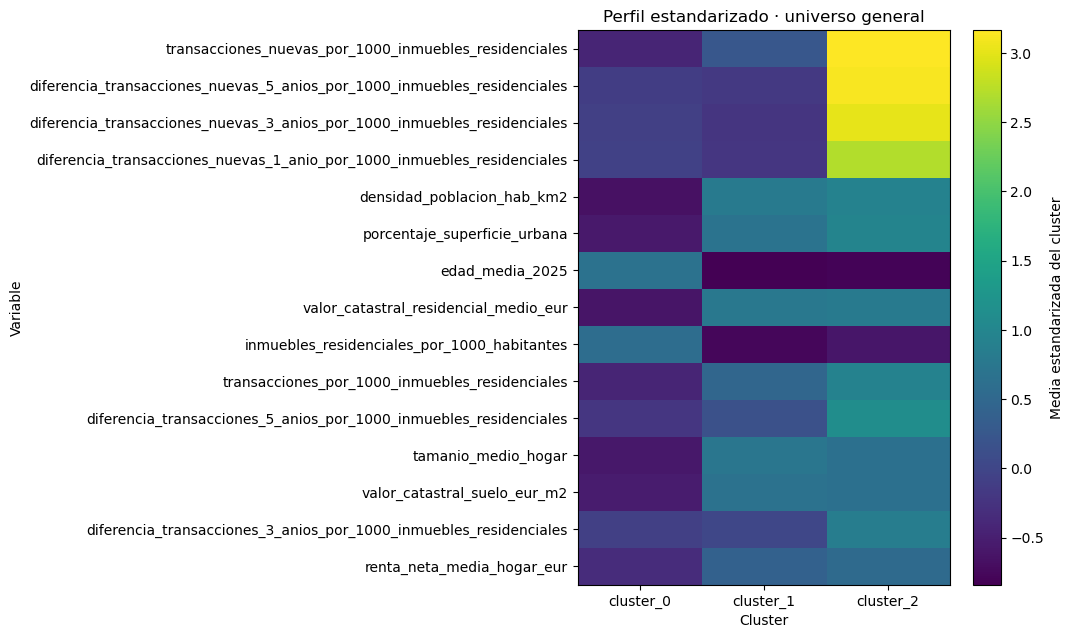

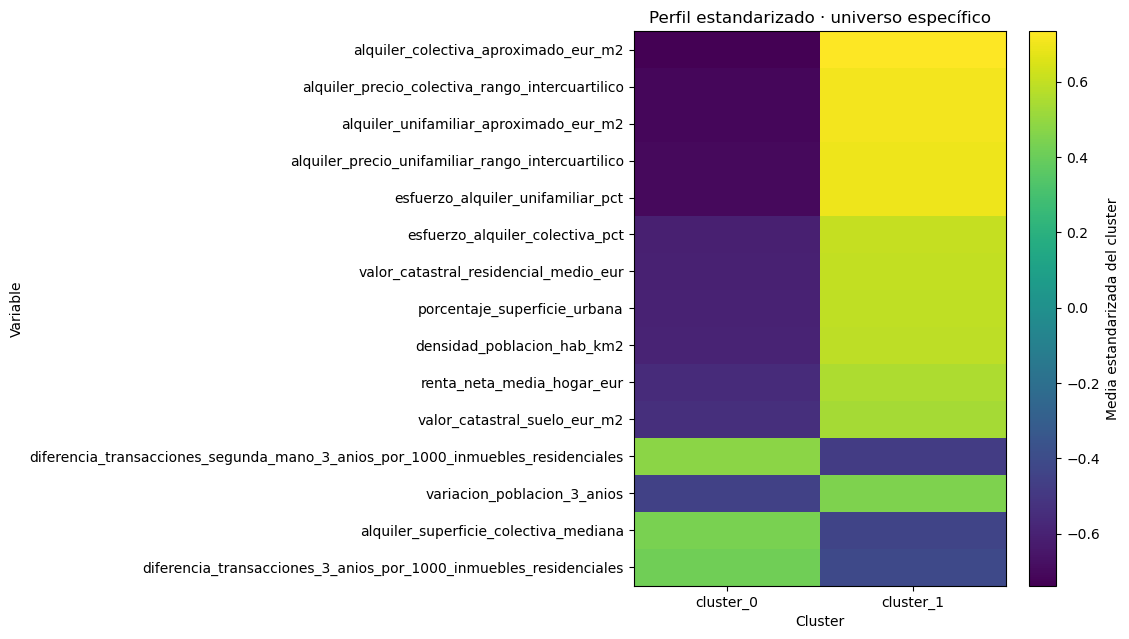

In [29]:
def plot_profile_heatmap(
    profile: pd.DataFrame,
    discriminators: pd.DataFrame,
    title: str,
    top_n: int = 15,
):
    top_features = (
        discriminators
        .head(top_n)["variable"]
        .tolist()
    )

    plot_data = profile.loc[top_features]

    plt.figure(
        figsize=(
            max(6, 1.6 * plot_data.shape[1]),
            max(6, 0.48 * plot_data.shape[0])
        )
    )

    ax = plt.gca()

    image = ax.imshow(
        plot_data.to_numpy(),
        aspect="auto",
    )

    ax.set_xticks(range(plot_data.shape[1]))
    ax.set_xticklabels(plot_data.columns)

    ax.set_yticks(range(plot_data.shape[0]))
    ax.set_yticklabels(plot_data.index)

    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Variable")

    plt.colorbar(
        image,
        ax=ax,
        label="Media estandarizada del cluster"
    )

    plt.show()


plot_profile_heatmap(
    profile_general_z,
    discriminators_general,
    "Perfil estandarizado · universo general"
)

plot_profile_heatmap(
    profile_specific_z,
    discriminators_specific,
    "Perfil estandarizado · universo específico"
)

Comentaremos por separado los resultados de los dos universos distintos.

### Universo general
Lo más llamativo de este mapa de calor es la gran característica que separa el tercer grupo: estos municipios presentan un gran número de transacciones de viviendas nuevas, tanto a nivel absoluto actual como en cuanto a su evolución durante los últimos años, lo que sugiere que este cluster está constituido por municipios en expansión, entornos urbanos en los que se fomenta la nueva construcción de viviendas. Más adelante veremos qué municipios representan este cluster.

Por otro lado, el primer cluster muestra principalmente una menor densidad de población, porcentaje de superficie urbana y valor catastral (tanto por inmueble residencial como por m2) y una mayor edad poblacional y número de inmuebles por habitante, lo que puede reflejar aquellos municipios más rurales en los que la demanda de vivienda actual no es tan pronunciada.

### Universo específico
Como ya hemos comentado, las variables que más separan los dos grupos en esta segmentación tienen que ver con el alquiler. El segundo cluster está constituido por municipios con un mayor precio del alquiler, tanto en vivienda colectiva como unifamiliar. Por otra parte, son municipios más urbanos, más densos poblacionalmente y, aunque presentan rentas mayores, el esfuerzo del alquiler es mayor en los municipios de este cluster.

Aunque no de manera tan pronunciada, sí que se observa otra conducta a priori: a pesar de que los municipios del segundo cluster muestran una variación de la población superior a la del primer grupo, la cantidad de transacciones por habitante se ha disminuido, lo que puede suponer un aumento del alquiler frente a la compraventa ante el aumento de los precios y las grandes dificultades para poder comprar una vivienda.

## Variables altas y bajas de cada cluster

Para facilitar la lectura se extraen automáticamente las variables en las que cada cluster se encuentra más por encima y más por debajo de la media global.

In [30]:
def cluster_highlights(
    profile: pd.DataFrame,
    n: int = 6
) -> pd.DataFrame:
    rows = []

    for cluster_col in profile.columns:
        s = profile[cluster_col].sort_values()

        for variable, value in s.head(n).items():
            rows.append({
                "cluster": cluster_col,
                "direccion": "bajo",
                "variable": variable,
                "media_estandarizada": value,
            })

        for variable, value in (
            s.tail(n)
            .sort_values(ascending=False)
            .items()
        ):
            rows.append({
                "cluster": cluster_col,
                "direccion": "alto",
                "variable": variable,
                "media_estandarizada": value,
            })

    return pd.DataFrame(rows)


highlights_general = cluster_highlights(
    profile_general_z
)

highlights_specific = cluster_highlights(
    profile_specific_z
)

print("Rasgos principales · GENERAL")
display(highlights_general.round(3))

print("Rasgos principales · ESPECÍFICO")
display(highlights_specific.round(3))

Rasgos principales · GENERAL


,cluster,direccion,variable,media_estandarizada
0,cluster_0,bajo,densidad_poblacion_hab_km2,-0.652
1,cluster_0,bajo,valor_catastral_residencial_medio_eur,-0.613
2,cluster_0,bajo,tamanio_medio_hogar,-0.572
3,cluster_0,bajo,porcentaje_superficie_urbana,-0.563
4,cluster_0,bajo,valor_catastral_suelo_eur_m2,-0.528
5,cluster_0,bajo,transacciones_nuevas_por_1000_inmuebles_reside...,-0.427
6,cluster_0,alto,edad_media_2025,0.663
7,cluster_0,alto,inmuebles_residenciales_por_1000_habitantes,0.598
8,cluster_0,alto,distancia_costa_km,0.342
9,cluster_0,alto,renta_neta_media_persona_eur,0.110


Rasgos principales · ESPECÍFICO


,cluster,direccion,variable,media_estandarizada
0,cluster_0,bajo,alquiler_colectiva_aproximado_eur_m2,-0.738
1,cluster_0,bajo,alquiler_precio_colectiva_rango_intercuartilico,-0.710
2,cluster_0,bajo,alquiler_unifamiliar_aproximado_eur_m2,-0.710
3,cluster_0,bajo,alquiler_precio_unifamiliar_rango_intercuartilico,-0.699
4,cluster_0,bajo,esfuerzo_alquiler_unifamiliar_pct,-0.698
5,cluster_0,bajo,esfuerzo_alquiler_colectiva_pct,-0.609
6,cluster_0,alto,diferencia_transacciones_segunda_mano_3_anios_...,0.479
7,cluster_0,alto,alquiler_superficie_colectiva_mediana,0.440
8,cluster_0,alto,diferencia_transacciones_3_anios_por_1000_inmu...,0.413
9,cluster_0,alto,edad_media_2025,0.326


# Interpretación en unidades originales

Mientras que los perfiles estandarizados indican qué variables diferencian los clusters, a continuación se muestran las medianas originales de las variables más discriminantes para observar estas diferencias entre clusters en unidades reales. Se prioriza la **mediana** porque muchas variables municipales presentan asimetría y valores extremos, como ya se vio durante el análisis exploratorio.

Estas medianas se calculan sobre los datos CURATED originales, antes de imputación, winsorización, logaritmos y escalado. Por ello son adecuadas para comunicar magnitudes, aunque no representan exactamente el espacio sobre el que se ajustó K-Means.

In [11]:
def raw_median_profile(
    data: pd.DataFrame,
    cluster_col: str,
    variables: list[str],
) -> pd.DataFrame:
    available = [
        c for c in variables
        if c in data.columns
    ]

    numeric = data[
        [cluster_col] + available
    ].copy()

    for c in available:
        numeric[c] = pd.to_numeric(
            numeric[c],
            errors="coerce"
        )

    medians = (
        numeric
        .groupby(cluster_col)[available]
        .median()
        .T
    )

    medians.columns = [
        f"cluster_{int(c)}"
        for c in medians.columns
    ]

    return medians


TOP_RAW_VARIABLES = 15

raw_vars_general = (
    discriminators_general
    .head(TOP_RAW_VARIABLES)["variable"]
    .tolist()
)

raw_vars_specific = (
    discriminators_specific
    .head(TOP_RAW_VARIABLES)["variable"]
    .tolist()
)

raw_medians_general = raw_median_profile(
    df_general,
    "cluster_general",
    raw_vars_general
)

raw_medians_specific = raw_median_profile(
    df_specific,
    "cluster_specific",
    raw_vars_specific
)

print("Medianas originales · GENERAL")
display(raw_medians_general.round(2))

print("Medianas originales · ESPECÍFICO")
display(raw_medians_specific.round(2))

Medianas originales · GENERAL


,cluster_0,cluster_1,cluster_2
transacciones_nuevas_por_1000_inmuebles_residenciales,0.00,0.25,8.20
diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,0.00,0.00,6.79
diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,0.00,0.00,6.28
diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,0.00,0.00,5.62
densidad_poblacion_hab_km2,5.08,62.39,105.44
porcentaje_superficie_urbana,0.37,2.74,4.44
edad_media_2025,54.72,44.72,43.98
valor_catastral_residencial_medio_eur,25251.18,49065.22,51636.16
inmuebles_residenciales_por_1000_habitantes,1282.05,561.48,566.01
transacciones_por_1000_inmuebles_residenciales,12.35,25.66,39.01


Medianas originales · ESPECÍFICO


,cluster_0,cluster_1
alquiler_colectiva_aproximado_eur_m2,4.00,6.86
alquiler_precio_colectiva_rango_intercuartilico,121.30,200.20
alquiler_unifamiliar_aproximado_eur_m2,2.44,4.31
alquiler_precio_unifamiliar_rango_intercuartilico,200.00,408.10
esfuerzo_alquiler_unifamiliar_pct,14.61,20.27
esfuerzo_alquiler_colectiva_pct,14.11,17.36
valor_catastral_residencial_medio_eur,45850.80,71686.03
porcentaje_superficie_urbana,3.44,16.07
densidad_poblacion_hab_km2,109.37,568.38
renta_neta_media_hogar_eur,31572.00,38682.00


# Municipios representativos de cada cluster

Para ayudar a dar significado económico y territorial a los grupos se identifican los municipios más próximos al **centro empírico del cluster en el espacio PCA**.

Estos municipios son los que presentan un perfil más cercano al patrón medio del cluster.

In [32]:
def representative_municipalities(
    X_pca: pd.DataFrame,
    data: pd.DataFrame,
    cluster_col: str,
    n_per_cluster: int = 10,
) -> pd.DataFrame:
    labels = data.loc[
        X_pca.index,
        cluster_col
    ].astype(int)

    meta_cols = [
        c for c in [
            "codigo_ine",
            "municipio",
            "provincia",
            "poblacion_2025",
            cluster_col,
        ]
        if c in data.columns
    ]

    rows = []

    for cluster in sorted(
        labels.unique()
    ):
        mask = labels == cluster
        X_cluster = X_pca.loc[mask]

        centroid = (
            X_cluster
            .mean(axis=0)
            .to_numpy()
        )

        distances = np.linalg.norm(
            X_cluster.to_numpy()
            - centroid,
            axis=1,
        )

        nearest = (
            pd.Series(
                distances,
                index=X_cluster.index,
                name="distancia_centro_pca",
            )
            .nsmallest(n_per_cluster)
        )

        block = data.loc[
            nearest.index,
            meta_cols
        ].copy()

        block["distancia_centro_pca"] = nearest
        block["cluster"] = int(cluster)

        rows.append(block)

    return pd.concat(
        rows,
        ignore_index=True
    )


representatives_general = representative_municipalities(
    X_general_pca,
    df_general,
    "cluster_general",
)

representatives_specific = representative_municipalities(
    X_specific_pca,
    df_specific,
    "cluster_specific",
)

print("Municipios representativos · GENERAL")
display(representatives_general.round(4))

print("Municipios representativos · ESPECÍFICO")
display(representatives_specific.round(4))

Municipios representativos · GENERAL


,codigo_ine,municipio,provincia,poblacion_2025,cluster_general,distancia_centro_pca,cluster
0,49157,Pino del Oro,Zamora,173,0,1.2612,0
1,32086,Viana do Bolo,Ourense,2715,0,1.2768,0
2,47145,San Miguel del Arroyo,Valladolid,641,0,1.3581,0
3,49064,Fariza,Zamora,487,0,1.4020,0
4,09103,Cilleruelo de Abajo,Burgos,209,0,1.4240,0
5,09246,Palacios de la Sierra,Burgos,662,0,1.4432,0
6,47077,Langayo,Valladolid,246,0,1.4446,0
7,16148,Palomares del Campo,Cuenca,556,0,1.4467,0
8,37044,Barruecopardo,Salamanca,409,0,1.4759,0
9,49046,Cerecinos de Campos,Zamora,231,0,1.4801,0


Municipios representativos · ESPECÍFICO


,codigo_ine,municipio,provincia,poblacion_2025,cluster_specific,distancia_centro_pca,cluster
0,47165,Tordesillas,Valladolid,8773,0,2.6290,0
1,24115,Ponferrada,León,63186,0,2.8604,0
2,50095,Ejea de los Caballeros,Zaragoza,17129,0,2.8922,0
3,10148,Plasencia,Cáceres,40132,0,2.9720,0
4,04053,Huércal-Overa,Almería,20860,0,3.0756,0
5,41072,Pedrera,Sevilla,5057,0,3.1376,0
6,41041,Estepa,Sevilla,12430,0,3.1379,0
7,25072,Cervera,Lleida,9603,0,3.1418,0
8,50008,Alagón,Zaragoza,7532,0,3.1677,0
9,14013,Cabra,Córdoba,19995,0,3.2006,0


# Distribución territorial

Para el clustering no se ha utilizado la provincia, el nombre del municipio ni las coordenadas como variables de entrada. Por tanto, una concentración espacial posterior no es una consecuencia directa de introducir la localización en el modelo, sino un indicio de cómo se distribuyen territorialmente los distintos patrones de comportamiento detectados del mercado inmobiliario español.

Se visualiza la distribución aproximada mediante longitud y latitud.

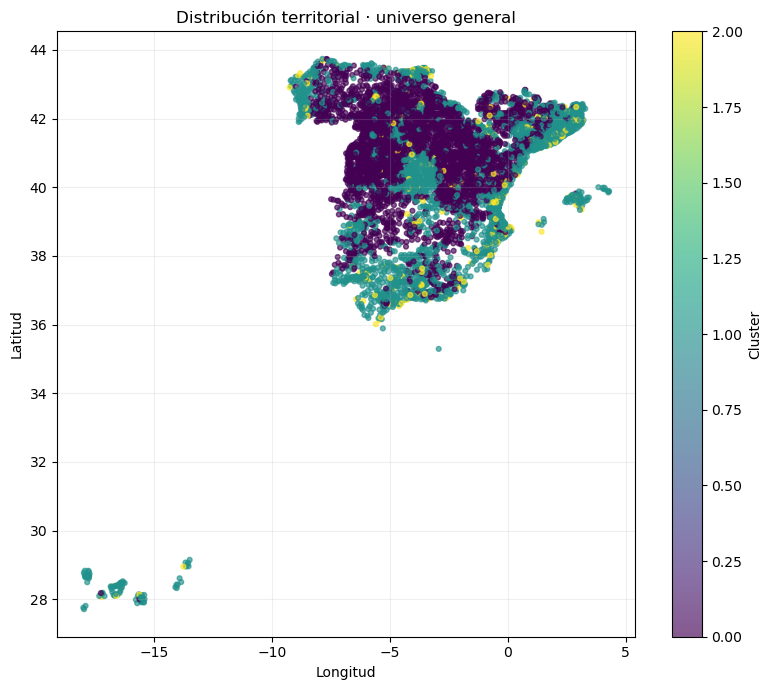

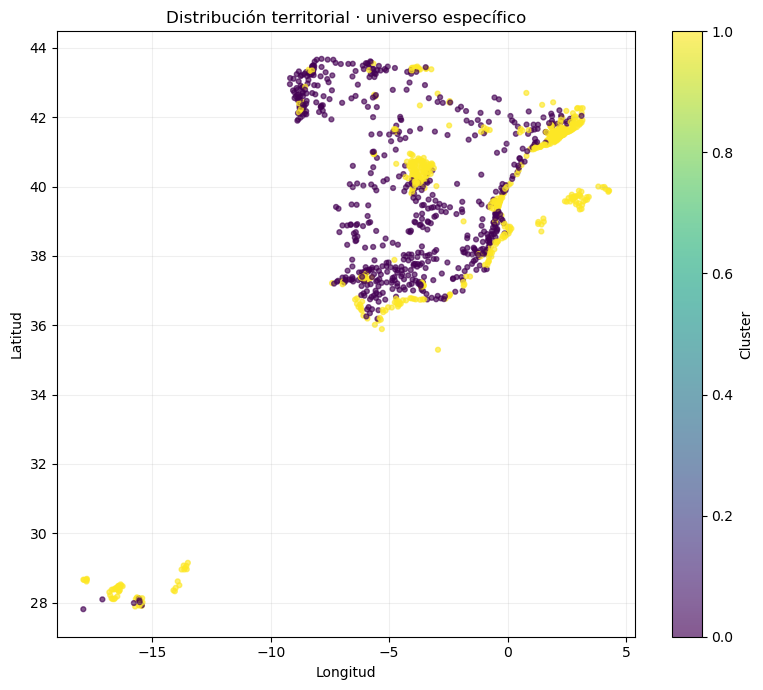

In [33]:
def plot_geographic_clusters(
    data: pd.DataFrame,
    cluster_col: str,
    title: str,
):
    plot_data = data.dropna(
        subset=[
            "longitud",
            "latitud",
            cluster_col
        ]
    ).copy()

    plt.figure(figsize=(8, 7))

    scatter = plt.scatter(
        pd.to_numeric(
            plot_data["longitud"],
            errors="coerce"
        ),
        pd.to_numeric(
            plot_data["latitud"],
            errors="coerce"
        ),
        c=plot_data[
            cluster_col
        ].astype(int),
        s=12,
        alpha=0.65,
    )

    plt.xlabel("Longitud")
    plt.ylabel("Latitud")
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.colorbar(
        scatter,
        label="Cluster"
    )
    plt.tight_layout()
    plt.show()


plot_geographic_clusters(
    df_general,
    "cluster_general",
    "Distribución territorial · universo general"
)

plot_geographic_clusters(
    df_specific,
    "cluster_specific",
    "Distribución territorial · universo específico"
)

## Concentración provincial

La siguiente tabla muestra, para cada cluster, qué provincias aportan más municipios. Se añade también una tabla normalizada por provincia para observar qué cluster domina dentro de cada territorio.

In [34]:
def top_provinces_by_cluster(
    data: pd.DataFrame,
    cluster_col: str,
    top_n: int = 10,
) -> pd.DataFrame:
    counts = (
        data
        .groupby([
            cluster_col,
            "provincia"
        ])
        .size()
        .rename("n_municipios")
        .reset_index()
    )

    counts["pct_dentro_cluster"] = (
        counts["n_municipios"]
        / counts.groupby(
            cluster_col
        )["n_municipios"]
        .transform("sum")
        * 100
    )

    return (
        counts
        .sort_values(
            [
                cluster_col,
                "n_municipios"
            ],
            ascending=[
                True,
                False
            ]
        )
        .groupby(
            cluster_col,
            group_keys=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )


def province_cluster_share(
    data: pd.DataFrame,
    cluster_col: str,
) -> pd.DataFrame:
    table = pd.crosstab(
        data["provincia"],
        data[cluster_col],
        normalize="index",
    ) * 100

    table["cluster_dominante"] = (
        table.idxmax(axis=1)
    )

    table["pct_cluster_dominante"] = (
        table.drop(
            columns=[
                "cluster_dominante"
            ]
        )
        .max(axis=1)
    )

    return table.sort_values(
        "pct_cluster_dominante",
        ascending=False,
    )


print("Provincias con más municipios por cluster · GENERAL")
display(
    top_provinces_by_cluster(
        df_general,
        "cluster_general"
    ).round(2)
)

print("Distribución de clusters dentro de cada provincia · GENERAL")
display(
    province_cluster_share(
        df_general,
        "cluster_general"
    ).round(2)
)

print("Provincias con más municipios por cluster · ESPECÍFICO")
display(
    top_provinces_by_cluster(
        df_specific,
        "cluster_specific"
    ).round(2)
)

Provincias con más municipios por cluster · GENERAL


,cluster_general,provincia,n_municipios,pct_dentro_cluster
0,0,Salamanca,322,7.60
1,0,Burgos,315,7.43
2,0,Guadalajara,233,5.50
3,0,Zamora,233,5.50
4,0,Ávila,222,5.24
5,0,Zaragoza,221,5.21
6,0,Teruel,206,4.86
7,0,Cuenca,203,4.79
8,0,Cáceres,197,4.65
9,0,Valladolid,180,4.25


Distribución de clusters dentro de cada provincia · GENERAL


cluster_general,0,1,2,cluster_dominante,pct_cluster_dominante
provincia,,,,,
Ceuta,0.00,100.00,0.00,1,100.00
Melilla,0.00,100.00,0.00,1,100.00
Soria,94.54,5.46,0.00,0,94.54
Zamora,93.95,5.65,0.40,0,93.95
Santa Cruz de Tenerife,1.85,90.74,7.41,1,90.74
Ávila,89.52,8.87,1.61,0,89.52
Salamanca,88.95,9.67,1.38,0,88.95
Cáceres,88.34,11.66,0.00,0,88.34
Las Palmas,5.88,88.24,5.88,1,88.24


Provincias con más municipios por cluster · ESPECÍFICO


,cluster_specific,provincia,n_municipios,pct_dentro_cluster
0,0,A Coruña,46,7.49
1,0,Sevilla,45,7.33
2,0,Murcia,30,4.89
3,0,Pontevedra,30,4.89
4,0,València/Valencia,29,4.72
5,0,Asturias,27,4.40
6,0,Alacant/Alicante,26,4.23
7,0,Jaén,26,4.23
8,0,Córdoba,24,3.91
9,0,Ciudad Real,22,3.58


# Relación entre la segmentación general y la específica

El universo específico añade información de alquiler y se restringe a municipios por encima del umbral poblacional que hemos situado en 5.000 habitantes. Por ello, resulta útil comprobar cómo se redistribuyen esos municipios respecto a la segmentación general.

In [35]:
general_specific_counts = pd.crosstab(
    df_specific["cluster_general"],
    df_specific["cluster_specific"],
)

general_specific_row_pct = pd.crosstab(
    df_specific["cluster_general"],
    df_specific["cluster_specific"],
    normalize="index",
) * 100

print(
    "Cruce general × específico · "
    "número de municipios"
)
display(
    general_specific_counts
)

print(
    "Cruce general × específico · "
    "% dentro de cada cluster general"
)
display(
    general_specific_row_pct.round(2)
)

Cruce general × específico · número de municipios


cluster_specific,0,1
cluster_general,,
0,12,0
1,557,529
2,45,88


Cruce general × específico · % dentro de cada cluster general


cluster_specific,0,1
cluster_general,,
0,100.00,0.00
1,51.29,48.71
2,33.83,66.17


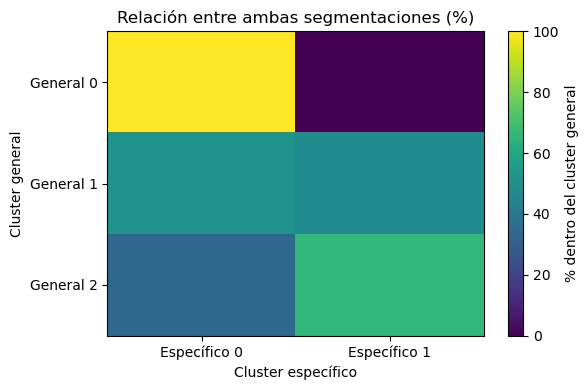

In [36]:
plt.figure(
    figsize=(
        max(
            6,
            1.5 * general_specific_row_pct.shape[1]
        ),
        max(
            4,
            1.2 * general_specific_row_pct.shape[0]
        )
    )
)

ax = plt.gca()

image = ax.imshow(
    general_specific_row_pct.to_numpy(),
    aspect="auto",
)

ax.set_xticks(
    range(
        general_specific_row_pct.shape[1]
    )
)
ax.set_xticklabels(
    [
        f"Específico {c}"
        for c in general_specific_row_pct.columns
    ]
)

ax.set_yticks(
    range(
        general_specific_row_pct.shape[0]
    )
)
ax.set_yticklabels(
    [
        f"General {c}"
        for c in general_specific_row_pct.index
    ]
)

ax.set_xlabel("Cluster específico")
ax.set_ylabel("Cluster general")
ax.set_title(
    "Relación entre ambas segmentaciones (%)"
)

plt.colorbar(
    image,
    ax=ax,
    label="% dentro del cluster general"
)

plt.tight_layout()
plt.show()

Como se puede apreciar en la imagen anterior, todos los municipios ubicados en el cluster 0 del universo general se ubican en el 0 del universo específico. Según las conclusiones obtenidas anteriormente, son municipios mayormente rurales, con un mayor número de inmuebles por habitante y menor densidad de población, de manera que resulta coherente que muestren precios del alquiler menores.

Por otra parte, también se observa que el cluster 2 del universo general (el más minoritario en cuanto a número de municipios) tiene más coincidencias con el cluster 1 del universo específico que con el 0. A nivel interpretable, esto nos quiere decir que estos municipios que, según hemos visto, son mayormente urbanos, se encuentran en expansión y presentan un mayor número de transacciones de inmuebles nuevos, también han visto encarecido el alquiler.

# Resumen automático para interpretar cada cluster

Esta tabla a modo de resumen reúne para cada grupo:

- número y peso de municipios;
- variables relativamente más altas;
- variables relativamente más bajas;
- algunos municipios representativos.

In [37]:
def compact_cluster_summary(
    data: pd.DataFrame,
    cluster_col: str,
    profile: pd.DataFrame,
    representatives: pd.DataFrame,
    n_features: int = 5,
    n_municipalities: int = 5,
) -> pd.DataFrame:
    sizes = cluster_sizes(
        data,
        cluster_col
    )

    rows = []

    clusters = sorted(
        data[
            cluster_col
        ]
        .dropna()
        .astype(int)
        .unique()
    )

    for cluster in clusters:
        col = f"cluster_{cluster}"
        s = profile[col].sort_values()

        low = ", ".join(
            s.head(
                n_features
            ).index.tolist()
        )

        high = ", ".join(
            s.tail(
                n_features
            )
            .sort_values(
                ascending=False
            )
            .index
            .tolist()
        )

        reps = (
            representatives.loc[
                representatives[
                    "cluster"
                ] == cluster,
                "municipio",
            ]
            .head(
                n_municipalities
            )
        )

        size_row = sizes.loc[
            sizes[
                "cluster"
            ] == cluster
        ].iloc[0]

        rows.append({
            "cluster": cluster,
            "n_municipios": int(
                size_row[
                    "n_municipios"
                ]
            ),
            "pct_municipios": float(
                size_row[
                    "pct_municipios"
                ]
            ),
            "rasgos_altos": high,
            "rasgos_bajos": low,
            "municipios_representativos": (
                ", ".join(
                    reps.astype(str)
                )
            ),
        })

    return pd.DataFrame(rows)


summary_general = compact_cluster_summary(
    df_general,
    "cluster_general",
    profile_general_z,
    representatives_general,
)

summary_specific = compact_cluster_summary(
    df_specific,
    "cluster_specific",
    profile_specific_z,
    representatives_specific,
)

print("Síntesis · GENERAL")
display(summary_general)

print("Síntesis · ESPECÍFICO")
display(summary_specific)

Síntesis · GENERAL


,cluster,n_municipios,pct_municipios,rasgos_altos,rasgos_bajos,municipios_representativos
0,0,4238,55.704522,"edad_media_2025, inmuebles_residenciales_por_1...","densidad_poblacion_hab_km2, valor_catastral_re...","Pino del Oro, Viana do Bolo, San Miguel del Ar..."
1,1,3042,39.984227,"densidad_poblacion_hab_km2, valor_catastral_re...","edad_media_2025, inmuebles_residenciales_por_1...","Nájera, Entrena, Segorbe, Barbastro, Víznar"
2,2,328,4.311251,transacciones_nuevas_por_1000_inmuebles_reside...,"edad_media_2025, inmuebles_residenciales_por_1...","Rotglà i Corberà, San Felices de Buelna, Onda,..."


Síntesis · ESPECÍFICO


,cluster,n_municipios,pct_municipios,rasgos_altos,rasgos_bajos,municipios_representativos
0,0,614,49.878148,diferencia_transacciones_segunda_mano_3_anios_...,"alquiler_colectiva_aproximado_eur_m2, alquiler...","Tordesillas, Ponferrada, Ejea de los Caballero..."
1,1,617,50.121852,"alquiler_colectiva_aproximado_eur_m2, alquiler...",diferencia_transacciones_segunda_mano_3_anios_...,"Sant Celoni, Girona, Masquefa, Reus, La Bisbal..."


# Exportar resultados de interpretación a S3

Se guardarán las tablas principales en:

`clustering/interpretation/reports/`

In [38]:
INTERPRETATION_PREFIX = "clustering/interpretation"

def save_dataframe_s3(
    data: pd.DataFrame,
    filename: str,
    index: bool = True,
) -> str:
    key = (
        f"{INTERPRETATION_PREFIX}"
        f"/reports/{filename}"
    )

    payload = data.to_csv(
        index=index
    ).encode("utf-8")

    s3_client.put_object(
        Bucket=BUCKET,
        Key=key,
        Body=payload,
        ContentType="text/csv",
    )

    uri = f"s3://{BUCKET}/{key}"
    print(f"Guardado → {uri}")

    return uri


save_dataframe_s3(
    sizes_general,
    "cluster_sizes_general.csv",
    index=False,
)
save_dataframe_s3(
    sizes_specific,
    "cluster_sizes_specific.csv",
    index=False,
)

save_dataframe_s3(
    profile_general_z,
    "standardized_profile_general.csv",
)
save_dataframe_s3(
    profile_specific_z,
    "standardized_profile_specific.csv",
)

save_dataframe_s3(
    discriminators_general,
    "discriminating_variables_general.csv",
    index=False,
)
save_dataframe_s3(
    discriminators_specific,
    "discriminating_variables_specific.csv",
    index=False,
)

save_dataframe_s3(
    raw_medians_general,
    "raw_medians_general.csv",
)
save_dataframe_s3(
    raw_medians_specific,
    "raw_medians_specific.csv",
)

save_dataframe_s3(
    representatives_general,
    "representative_municipalities_general.csv",
    index=False,
)
save_dataframe_s3(
    representatives_specific,
    "representative_municipalities_specific.csv",
    index=False,
)

save_dataframe_s3(
    general_specific_counts,
    "general_specific_cross_counts.csv",
)
save_dataframe_s3(
    general_specific_row_pct,
    "general_specific_cross_row_pct.csv",
)

save_dataframe_s3(
    summary_general,
    "interpretation_summary_general.csv",
    index=False,
)
save_dataframe_s3(
    summary_specific,
    "interpretation_summary_specific.csv",
    index=False,
)

Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/cluster_sizes_general.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/cluster_sizes_specific.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/standardized_profile_general.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/standardized_profile_specific.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/discriminating_variables_general.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/discriminating_variables_specific.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/raw_medians_general.csv
Guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/raw_medians_specific.

's3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/interpretation/reports/interpretation_summary_specific.csv'

# Asignación de nombres interpretativos

Después la interpretación de los resultados y de analizar cuáles han sido las variables más influyentes en cada una de las dos segmentaciones, podemos asignar los siguientes nombres a los distintos grupos obtenidos:

### Universo general

- Cluster 0: **municipios rurales, envejecidos y con poca actividad inmobiliaria**
- Cluster 1: **municipios urbanos, con actividad inmobiliaria moderada y mayoritariamente de segunda mano**
- Cluster 2: **municipios en expansión, zonas densas con nuevas construcciones**

### Universo específico (más de 5.000 habitantes)

- Cluster 0: **municipios más asequibles, con menor densidad de población y rentas más bajas**
- Cluster 1: **municipios encarecidos, con un mayor crecimiento poblacional, estancamiento de la compraventa y esfuerzo del alquiler elevado**